In [ ]:
%pip install pandas numpy matplotlib seaborn scikit-learn openpyxl

In [ ]:
import os

print(os.getcwd())
print(os.path.exists("EastWestAirlines.xlsx"))

/content
True


In [ ]:
import pandas as pd

excel = pd.ExcelFile("EastWestAirlines.xlsx")
print(excel.sheet_names)

['Description', 'data']


In [ ]:

import os

print("Current folder:", os.getcwd())
print("Excel file found:", os.path.exists("EastWestAirlines.xlsx"))


Current folder: /content
Excel file found: True


In [ ]:

import pandas as pd

excel = pd.ExcelFile("EastWestAirlines.xlsx")
print(excel.sheet_names)


['Description', 'data']


In [ ]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

df = pd.read_excel("EastWestAirlines.xlsx", sheet_name="data")

print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())

df = df.dropna().copy()

features = df.drop(columns=["ID#"]).copy()

outlier_cols = [
    "Balance", "Qual_miles", "Bonus_miles",
    "Bonus_trans", "Flight_miles_12mo", "Flight_trans_12"
]

limits = features[outlier_cols].quantile(0.99)
features = features.loc[
    (features[outlier_cols] <= limits).all(axis=1)
].copy()

for col in outlier_cols:
    q1 = features[col].quantile(0.25)
    q3 = features[col].quantile(0.75)
    iqr = q3 - q1

    features[col] = features[col].clip(
        lower=q1 - 1.5 * iqr,
        upper=q3 + 1.5 * iqr
    )

scaler = StandardScaler()
X = scaler.fit_transform(features)

print("Processed records:", X.shape[0])
print("Number of features:", X.shape[1])
print("Preprocessing completed!")


Dataset shape: (3999, 12)
Missing values: 0
Processed records: 3816
Number of features: 11
Preprocessing completed!


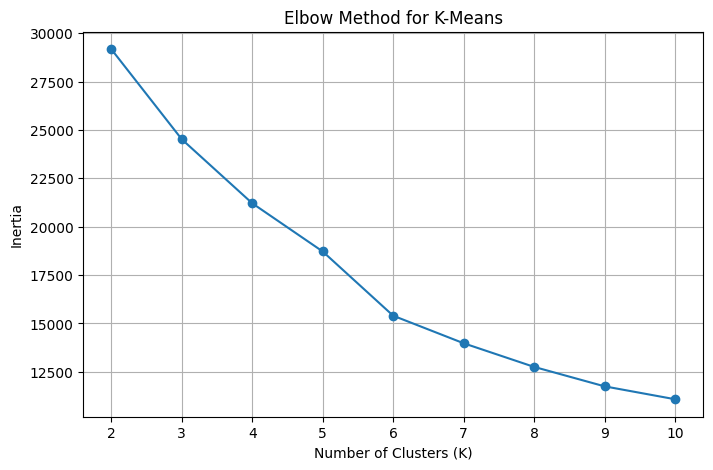

In [ ]:

inertias = []
K_values = range(2, 11)

for k in K_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(K_values), inertias, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-Means")
plt.xticks(list(K_values))
plt.grid(True)
plt.show()


In [ ]:

kmeans_results = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    labels = model.fit_predict(X)

    score = silhouette_score(
        X,
        labels,
        sample_size=min(2000, len(X)),
        random_state=42
    )

    kmeans_results.append({
        "K": k,
        "Inertia": round(model.inertia_, 2),
        "Silhouette Score": round(score, 4)
    })

kmeans_table = pd.DataFrame(kmeans_results)

print(kmeans_table.to_string(index=False))


 K  Inertia  Silhouette Score
 2 29172.79            0.2925
 3 24517.56            0.3089
 4 21209.75            0.3087
 5 18718.46            0.2991
 6 15398.80            0.3136
 7 13975.02            0.2287
 8 12752.87            0.2415
 9 11748.02            0.2474
10 11081.65            0.2472


In [ ]:

best_k = int(
    kmeans_table.loc[
        kmeans_table["Silhouette Score"].idxmax(),
        "K"
    ]
)

kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X)

print("Selected K:", best_k)
print("Silhouette Score:", round(
    silhouette_score(
        X,
        kmeans_labels,
        sample_size=min(2000, len(X)),
        random_state=42
    ), 4
))
print("Cluster sizes:")
print(pd.Series(kmeans_labels).value_counts().sort_index())


Selected K: 6
Silhouette Score: 0.3136
Cluster sizes:
0    1021
1     373
2    1783
3       9
4      41
5     589
Name: count, dtype: int64


Hirearcheal clustering

In [ ]:

hierarchical_results = []

for linkage in ["ward", "complete", "average"]:
    for k in [2, 3, 4, 5, 6]:

        model = AgglomerativeClustering(
            n_clusters=k,
            linkage=linkage
        )

        labels = model.fit_predict(X)

        score = silhouette_score(
            X,
            labels,
            sample_size=min(2000, len(X)),
            random_state=42
        )

        hierarchical_results.append({
            "Linkage": linkage,
            "Clusters": k,
            "Silhouette Score": round(score, 4)
        })

hierarchical_table = pd.DataFrame(hierarchical_results)

print("Hierarchical Clustering Comparison")
print(hierarchical_table.to_string(index=False))


Hierarchical Clustering Comparison
 Linkage  Clusters  Silhouette Score
    ward         2            0.2712
    ward         3            0.2095
    ward         4            0.2223
    ward         5            0.2257
    ward         6            0.2406
complete         2            0.7986
complete         3            0.6305
complete         4            0.6298
complete         5            0.5239
complete         6            0.5118
 average         2            0.7986
 average         3            0.7653
 average         4            0.6298
 average         5            0.5239
 average         6            0.5240


In [ ]:

best_h = hierarchical_table.loc[
    hierarchical_table["Silhouette Score"].idxmax()
]

best_linkage = best_h["Linkage"]
best_h_k = int(best_h["Clusters"])

hierarchical = AgglomerativeClustering(
    n_clusters=best_h_k,
    linkage=best_linkage
)

hierarchical_labels = hierarchical.fit_predict(X)

print("Best linkage:", best_linkage)
print("Selected number of clusters:", best_h_k)
print("Best silhouette score:",
      best_h["Silhouette Score"])

print("\nCluster sizes:")
print(
    pd.Series(hierarchical_labels)
    .value_counts()
    .sort_index()
)


Best linkage: complete
Selected number of clusters: 2
Best silhouette score: 0.7986

Cluster sizes:
0    3807
1       9
Name: count, dtype: int64


DBSCAN

In [ ]:

dbscan_results = []

eps_values = [1.5, 2.0, 2.5, 3.0, 3.5, 4.0]
min_samples_values = [5, 10, 15]

best_dbscan_score = -1
best_dbscan = None
best_dbscan_labels = None

for eps in eps_values:
    for min_samples in min_samples_values:

        model = DBSCAN(
            eps=eps,
            min_samples=min_samples
        )

        labels = model.fit_predict(X)

        n_clusters = len(set(labels) - {-1})
        noise_count = np.sum(labels == -1)
        score = np.nan

        # Exclude noise points when calculating silhouette score
        non_noise = labels != -1
        clean_labels = labels[non_noise]
        clean_X = X[non_noise]

        if (
            n_clusters >= 2
            and len(np.unique(clean_labels)) < len(clean_labels)
        ):
            score = silhouette_score(
                clean_X,
                clean_labels,
                sample_size=min(2000, len(clean_X)),
                random_state=42
            )

        dbscan_results.append({
            "Epsilon": eps,
            "Min Samples": min_samples,
            "Clusters": n_clusters,
            "Noise Points": int(noise_count),
            "Silhouette Score": (
                round(score, 4)
                if np.isfinite(score) else np.nan
            )
        })

        if np.isfinite(score) and score > best_dbscan_score:
            best_dbscan_score = score
            best_dbscan = model
            best_dbscan_labels = labels.copy()

dbscan_table = pd.DataFrame(dbscan_results)

print("DBSCAN Parameter Comparison")
print(dbscan_table.to_string(index=False))


DBSCAN Parameter Comparison
 Epsilon  Min Samples  Clusters  Noise Points  Silhouette Score
     1.5            5         4            50            0.2368
     1.5           10         3            76            0.2308
     1.5           15         2           138            0.2445
     2.0            5         4            32            0.2440
     2.0           10         3            40            0.2363
     2.0           15         2            54            0.2328
     2.5            5         3            25            0.5109
     2.5           10         2            35            0.5181
     2.5           15         2            36            0.5142
     3.0            5         3            16            0.5216
     3.0           10         3            19            0.5221
     3.0           15         2            33            0.5192
     3.5            5         3            13            0.5200
     3.5           10         3            15            0.5135
     3.5    

In [ ]:

if best_dbscan is not None:
    print("Best DBSCAN Configuration")
    print("Epsilon:", best_dbscan.eps)
    print("Min Samples:", best_dbscan.min_samples)
    print("Silhouette Score:", round(best_dbscan_score, 4))

    print(
        "Number of clusters:",
        len(set(best_dbscan_labels) - {-1})
    )

    print(
        "Noise points:",
        int(np.sum(best_dbscan_labels == -1))
    )

    print("\nCluster sizes, including noise if present:")
    print(
        pd.Series(best_dbscan_labels)
        .value_counts()
        .sort_index()
    )
else:
    print("No valid DBSCAN configuration found.")
    print("Try testing larger eps values.")


Best DBSCAN Configuration
Epsilon: 4.0
Min Samples: 15
Silhouette Score: 0.5287
Number of clusters: 2
Noise points: 26

Cluster sizes, including noise if present:
-1      26
 0    3763
 1      27
Name: count, dtype: int64


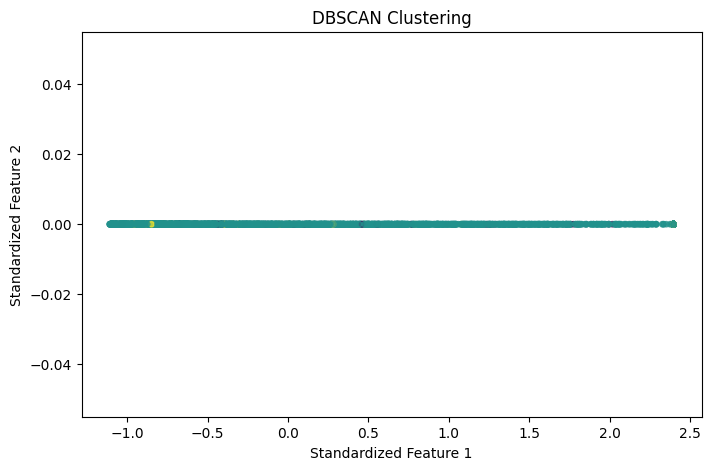

In [ ]:

if best_dbscan_labels is not None:
    plt.figure(figsize=(8, 5))

    plt.scatter(
        X[:, 0],
        X[:, 1],
        c=best_dbscan_labels,
        cmap="viridis",
        s=15,
        alpha=0.7
    )

    plt.xlabel("Standardized Feature 1")
    plt.ylabel("Standardized Feature 2")
    plt.title("DBSCAN Clustering")
    plt.show()
else:
    print("No valid DBSCAN clustering to visualize.")


In [ ]:

output = df.loc[features.index].copy()

output["KMeans_Cluster"] = kmeans_labels
output["Hierarchical_Cluster"] = hierarchical_labels

output["DBSCAN_Cluster"] = (
    best_dbscan_labels
    if best_dbscan_labels is not None
    else np.full(len(output), -1)
)

output.to_csv("clustering_results.csv", index=False)
kmeans_table.to_csv("kmeans_comparison.csv", index=False)
hierarchical_table.to_csv("hierarchical_comparison.csv", index=False)
dbscan_table.to_csv("dbscan_comparison.csv", index=False)

print("All results saved successfully!")



All results saved successfully!


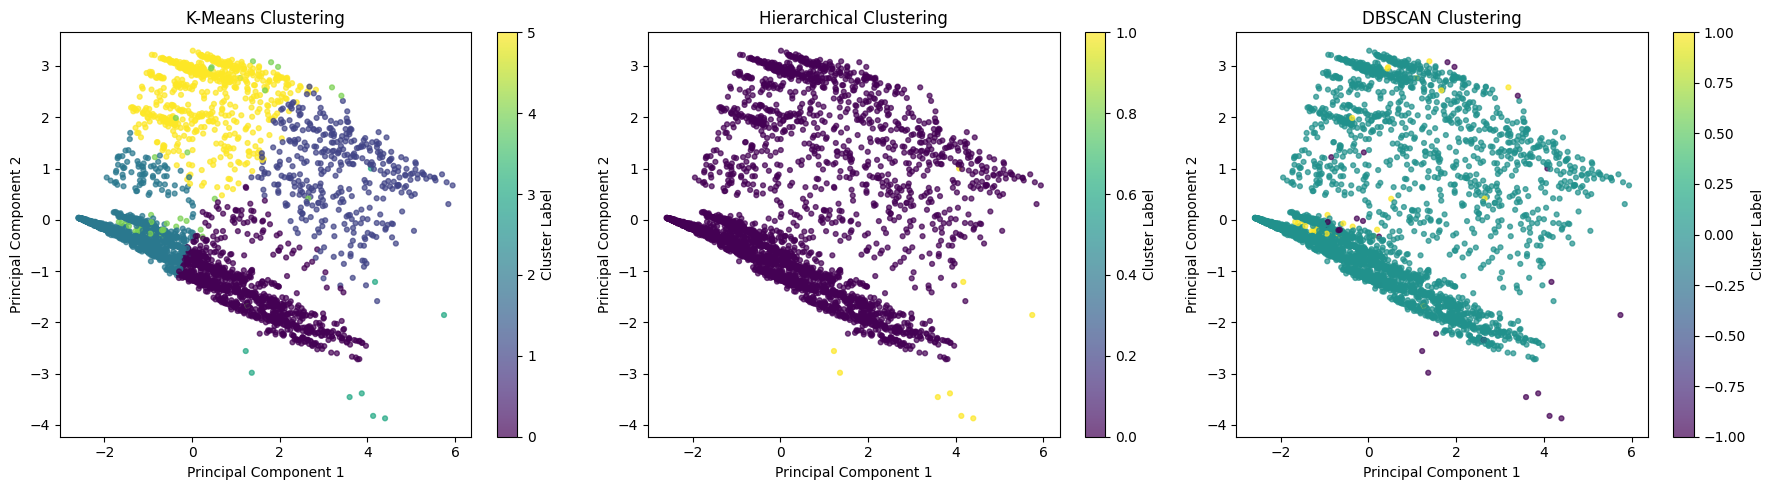

In [ ]:
# Visualize clustering results using PCA
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

results = [
    ("K-Means Clustering", kmeans_labels),
    ("Hierarchical Clustering", hierarchical_labels),
    ("DBSCAN Clustering", best_dbscan_labels)
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (title, labels) in zip(axes, results):
    if labels is None:
        ax.set_title(title + " (No valid result)")
        continue

    scatter = ax.scatter(
        X_pca[:, 0],
        X_pca[:, 1],
        c=labels,
        cmap="viridis",
        s=12,
        alpha=0.7
    )

    ax.set_title(title)
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")

    fig.colorbar(scatter, ax=ax, label="Cluster Label")

plt.tight_layout()
plt.show()